<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IRIS DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8  setosa

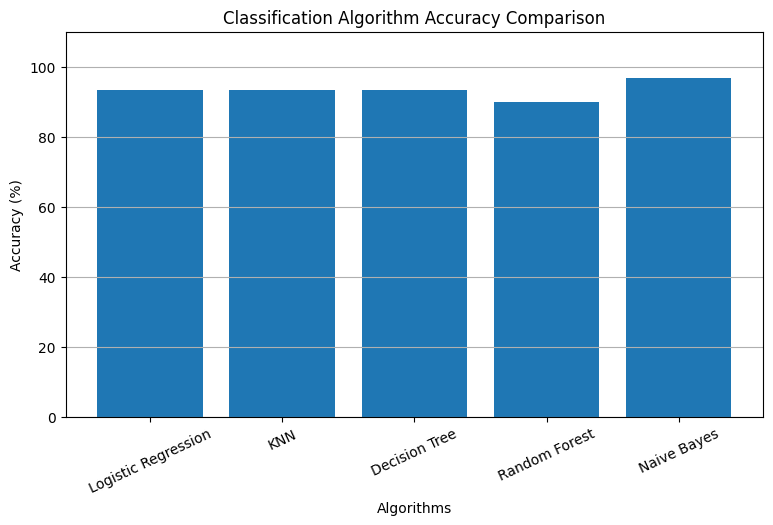

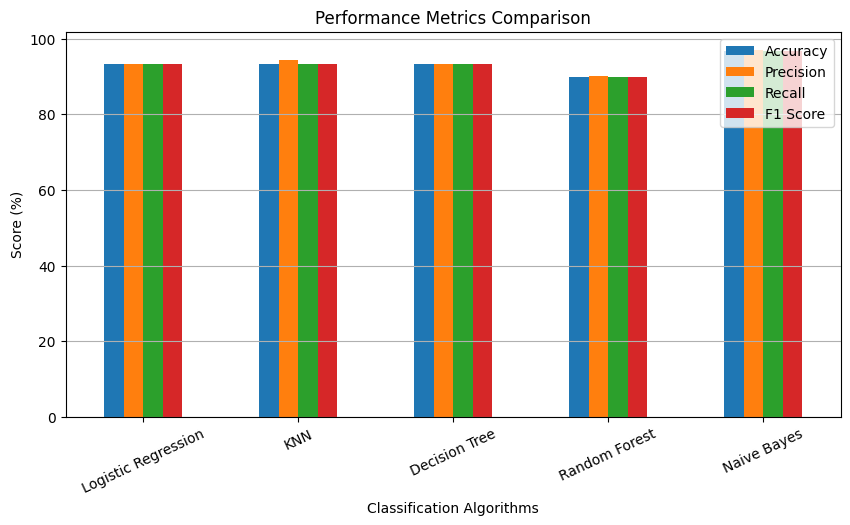


BEST PERFORMING ALGORITHM
Algorithm: Naive Bayes
Accuracy: 96.67 %


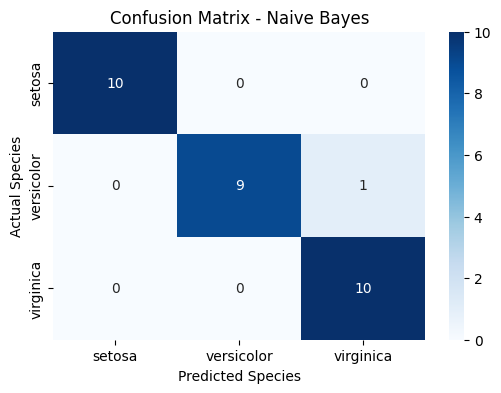


NEW FLOWER PREDICTION
Predicted Species: setosa


In [1]:
# EXPERIMENT 16: COMPARISON OF CLASSIFICATION ALGORITHMS

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# Step 2: Load dataset
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("IRIS DATASET")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

# Step 4: Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Define algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    'Naive Bayes': GaussianNB()
}

# Step 6: Train and evaluate models
results = []

for name, model in models.items():

    if name in ['Logistic Regression', 'KNN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy * 100,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1 Score': f1 * 100
    })

# Step 7: Display comparison table
result_df = pd.DataFrame(results)

print("\nALGORITHM PERFORMANCE COMPARISON")
print(result_df.round(2).to_string(index=False))

# Step 8: Accuracy comparison graph
plt.figure(figsize=(9, 5))

plt.bar(
    result_df['Algorithm'],
    result_df['Accuracy']
)

plt.title("Classification Algorithm Accuracy Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=25)
plt.ylim(0, 110)
plt.grid(axis='y')
plt.show()

# Step 9: Compare all performance metrics
result_df.set_index('Algorithm')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(10, 5))

plt.title("Performance Metrics Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Classification Algorithms")
plt.xticks(rotation=25)
plt.legend()
plt.grid(axis='y')
plt.show()

# Step 10: Best algorithm
best_algorithm = result_df.loc[
    result_df['Accuracy'].idxmax()
]

print("\nBEST PERFORMING ALGORITHM")
print("Algorithm:", best_algorithm['Algorithm'])
print("Accuracy:", round(best_algorithm['Accuracy'], 2), "%")

# Step 11: Confusion Matrix for best algorithm
best_name = best_algorithm['Algorithm']
best_model = models[best_name]

if best_name in ['Logistic Regression', 'KNN']:
    best_pred = best_model.predict(X_test_scaled)
else:
    best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

# Step 12: Predict a new sample
new_flower = [[5.1, 3.5, 1.4, 0.2]]

if best_name in ['Logistic Regression', 'KNN']:
    new_flower = scaler.transform(new_flower)

prediction = best_model.predict(new_flower)

print("\nNEW FLOWER PREDICTION")
print("Predicted Species:", iris.target_names[prediction[0]])